# Getting more candidate motifs: comparing design choices

Mouse 720762. Goal: as many candidate motifs as possible from a recording, to be filtered later by validation
against neuron activity. Each idea is a switch in `src/candidate_motifs.py`, run alone and in combination.

| Code | Idea | Switch |
|---|---|---|
| A | Gaussian-mixture poles instead of mirror-image poles | `poles="gmm"` (2 components) or `"gmm3"` (3: low, middle, high) |
| B | No binarization: cluster the z-scored values | `binarize=False` |
| C | Baseline as a forced label for quiet seconds | `baseline=True` |
| D | Common average reference for EEG | EEG minus the mean of all valid EEG channels |
| E | More channels, union of candidates | all 26 EEG channels and 45 LFP regions |
| F | Relaxed time criterion: present in any chunk | `significance="any"` |
| G | Finer time bins (spontaneous, electrical, visual; early and late isoflurane) | `bins="fine"` |
| P | Keep every candidate, with its p-value as a score | `significance="none"` |

Bands: the same 10 overlapping bands as the 2026-11-01 report (1–4, 3–6, 5–9, 8–12, 10–15, 13–20, 18–30, 25–40,
35–55 and 50–80 Hz), so the results compare directly with it. Two candidates count as the same if their band patterns correlate at
r ≥ 0.9 (same sign: a pole and its opponent are different candidates). "Broadband-like" = at most 1 band of the
minority sign. "Stimulus-free" bins exclude both electrical and visual stimulus blocks (the report excluded only the
electrical ones), so the standard-bin counts are close to, but not identical with, the report's.

This is exploratory: no validation against neuron activity yet. The last section plots the candidates and their strength
over the recording alongside isoflurane, stimuli, running and pupil size.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import candidate_motifs as cm
from src import session_data as sd
from src.channel_sweep import list_signals
from src.state_motifs import band_labels
%matplotlib inline

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
CAR = REPO / "data" / "processed" / "candidate_motifs" / "eeg_car_mean.npz"
OUT = REPO / "data" / "out" / "2026-11-08_candidate_motifs"
OUT.mkdir(parents=True, exist_ok=True)
names = band_labels()

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

io, nwb = sd.open_nwb(NWB)
info = sd.read_info(nwb, NWB.name)
signals = list_signals(nwb)
cm.car_reference(nwb, CAR)
beh = nwb.processing["behavior"]
rs = beh["BehavioralTimeSeries"]["running_speed"]
run_speed = rs.data[:]
run_t = rs.timestamps[:] if rs.timestamps is not None else rs.starting_time + np.arange(run_speed.size) / rs.rate
pw = beh["PupilTracking"]["pupil_width"]
pupil, pupil_t = pw.data[:], pw.timestamps[:]
io.close()
pd.DataFrame({b: {"intervals": [(round(a), round(c)) for a, c in v], "seconds": round(sum(c - a for a, c in v))}
              for b, v in cm.time_bins(info).items()}).T

,intervals,seconds
awake,"[(27, 737), (2438, 2583), (3163, 3254)]",947
isoflurane,"[(3452, 4633), (6334, 6466), (7039, 7114)]",1388
awake_electrical,"[(762, 2413)]",1651
awake_visual,"[(2608, 3138)]",530
iso_early,"[(3452, 4633)]",1181
iso_electrical,"[(4658, 6309)]",1651
iso_visual,"[(6491, 7014)]",523
iso_late,"[(6334, 6466), (7039, 7114)]",207


## 1. Each idea on its own, on deep prelimbic LFP (PL5)

In [2]:
V = cm.Variant
core = [
    V("strict (Mishler)", significance="strict"),
    V("relaxed (current)"),
    V("A: GMM poles", poles="gmm"),
    V("A+C: GMM3 poles", poles="gmm3"),
    V("B: continuous", binarize=False),
    V("A+B", binarize=False, poles="gmm3"),
    V("C: + baseline", baseline=True),
    V("F: any chunk", significance="any"),
    V("G: fine bins", bins="fine"),
    V("G+F", bins="fine", significance="any"),
    V("P: no filter", significance="none"),
    V("G+P", bins="fine", significance="none"),
    V("max: G+P+A+C", bins="fine", significance="none", poles="gmm3", baseline=True),
]
pl5 = cm.run_signal(NWB, "lfp_PL5", ("lfp", "probeF", "PL5"), core, keep_expression=True)

def summarize(cands, variants):
    rows = []
    for v in variants:
        c = [x for x in cands if x.variant == v.name]
        poles = [x for x in c if x.kind == "pole"]
        u = cm.unique(poles)
        rows.append({"variant": v.name, "pole candidates": len(poles), "distinct": len(u),
                     "distinct, not broadband": sum(not x.broadband for x in u),
                     "bins with candidates": len({x.bin for x in poles}),
                     "baseline labels": sum(x.kind == "baseline" for x in c)})
    return pd.DataFrame(rows).set_index("variant")

summary = summarize(pl5, core)
summary

,pole candidates,distinct,"distinct, not broadband",bins with candidates,baseline labels
variant,,,,,
strict (Mishler),4,4,2,1,0
relaxed (current),4,4,2,1,0
A: GMM poles,4,4,0,1,0
A+C: GMM3 poles,4,4,0,1,0
B: continuous,0,0,0,0,0
A+B,0,0,0,0,0
C: + baseline,4,4,2,1,2
F: any chunk,4,4,2,1,0
G: fine bins,22,18,10,6,0


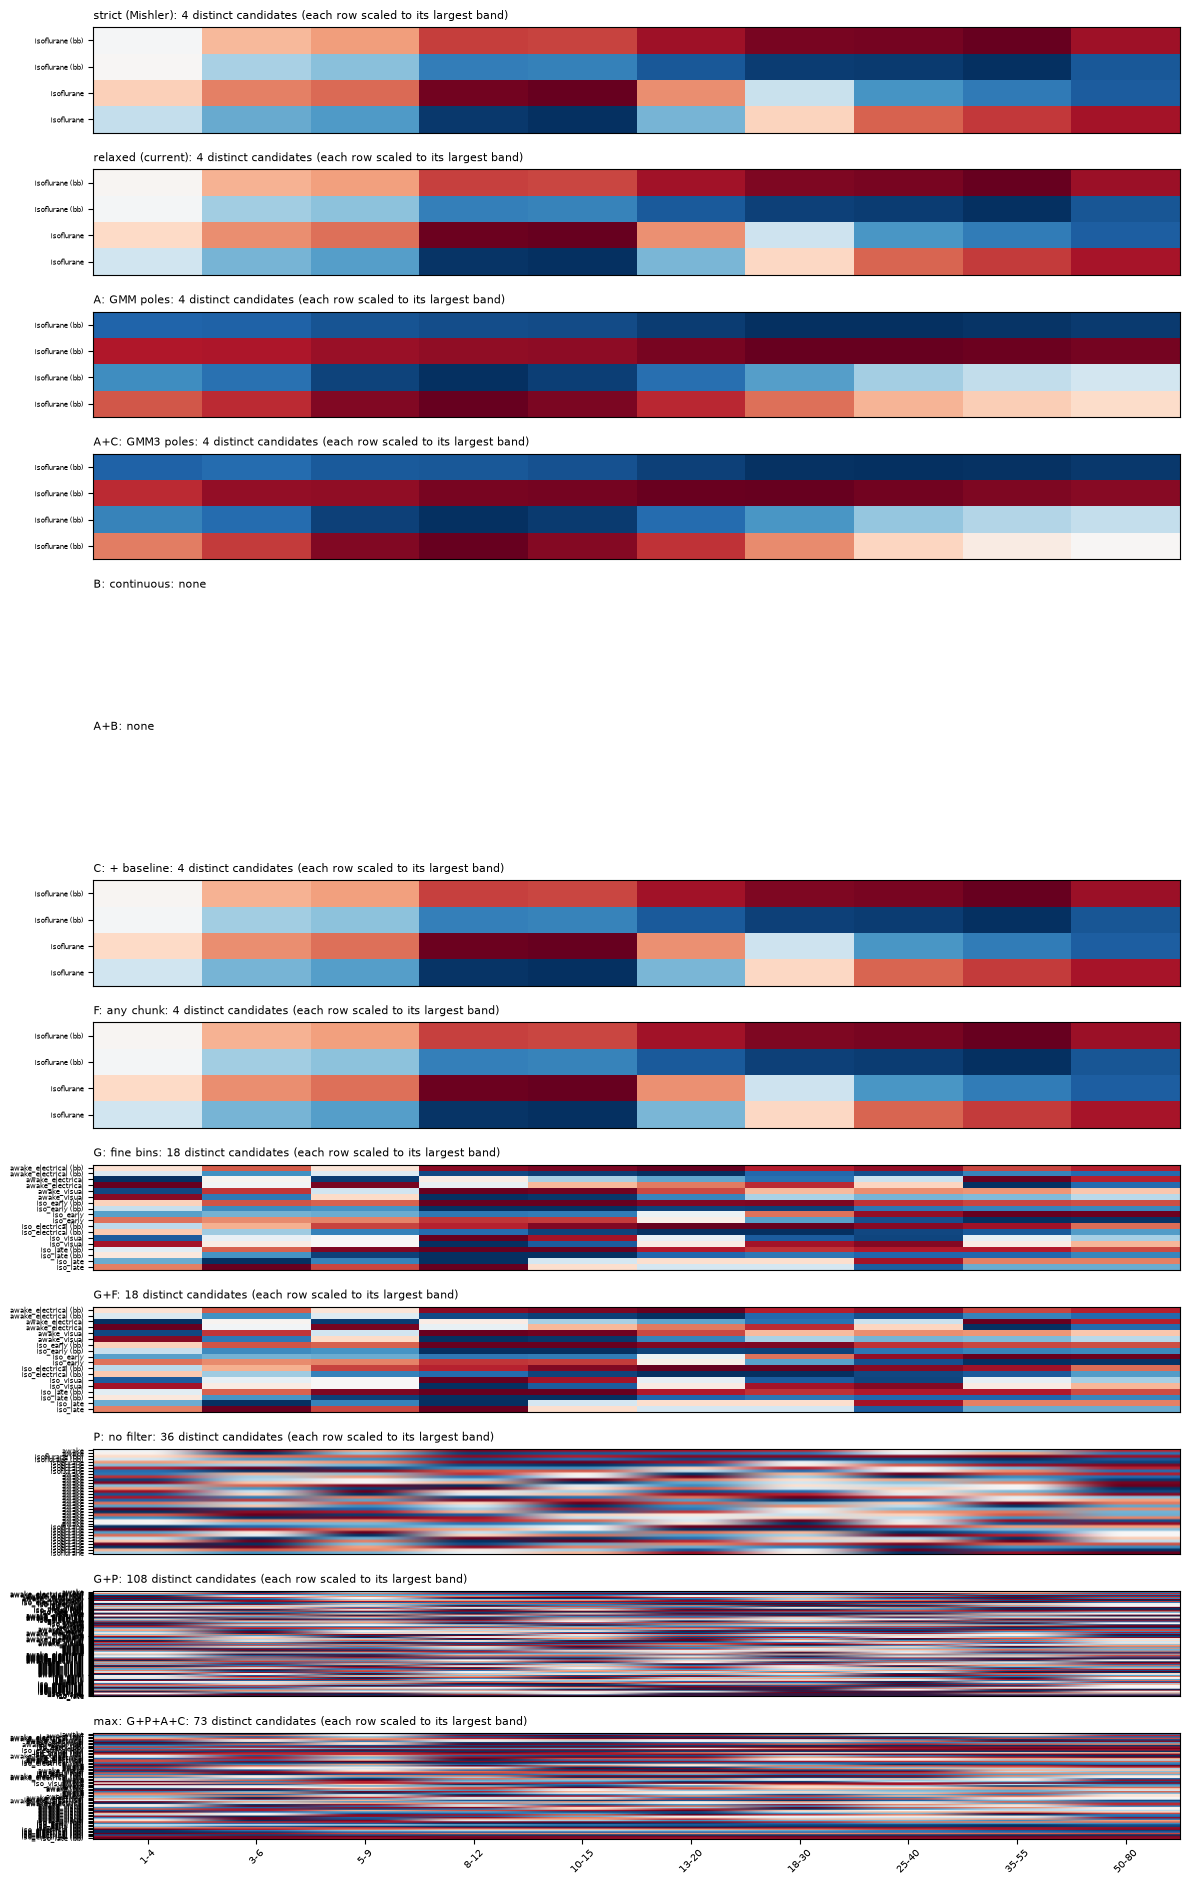

In [3]:
fig, axes = plt.subplots(len(core), 1, figsize=(12, 1.15 * len(core) + 4))
for ax, v in zip(axes, core):
    u = cm.unique([x for x in pl5 if x.variant == v.name])
    if not u:
        ax.axis("off"); ax.set_title(f"{v.name}: none", fontsize=8, loc="left"); continue
    M = np.array([x.template / np.abs(x.template).max() for x in u])
    ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_yticks(range(len(u)), [f"{x.bin}{' (bb)' if x.broadband else ''}" for x in u], fontsize=5)
    ax.set_xticks([])
    ax.set_title(f"{v.name}: {len(u)} distinct candidates (each row scaled to its largest band)", fontsize=8, loc="left")
axes[-1].set_xticks(range(len(names)), names, rotation=45, fontsize=7)
fig.tight_layout(); save(fig, "1_pl5_candidates_by_variant"); plt.show()

## 2. Do Gaussian-mixture poles differ from mirror-image poles?

For each motif axis: correlation between the low pole and the *negative* of the high pole (1 = exact mirror images), and the ratio of their strengths.

In [4]:
rows = []
for name in ("A: GMM poles", "A+C: GMM3 poles", "A+B"):
    c = [x for x in pl5 if x.variant == name and x.kind == "pole"]
    for lo, hi in zip(c[::2], c[1::2]):
        rows.append({"variant": name, "bin": lo.bin, "low vs -high (r)": np.corrcoef(lo.template, -hi.template)[0, 1],
                     "strength ratio high/low": np.linalg.norm(hi.template) / np.linalg.norm(lo.template)})
asym = pd.DataFrame(rows)
asym.round(2)

,variant,bin,low vs -high (r),strength ratio high/low
0,A: GMM poles,isoflurane,1.0,0.30
1,A: GMM poles,isoflurane,1.0,1.31
2,A+C: GMM3 poles,isoflurane,0.6,0.43
3,A+C: GMM3 poles,isoflurane,1.0,1.68


## 3. Redundancy: which variants find the same candidates?

Share of the row variant's candidates that also appear (r ≥ 0.9, same sign) in the column variant.

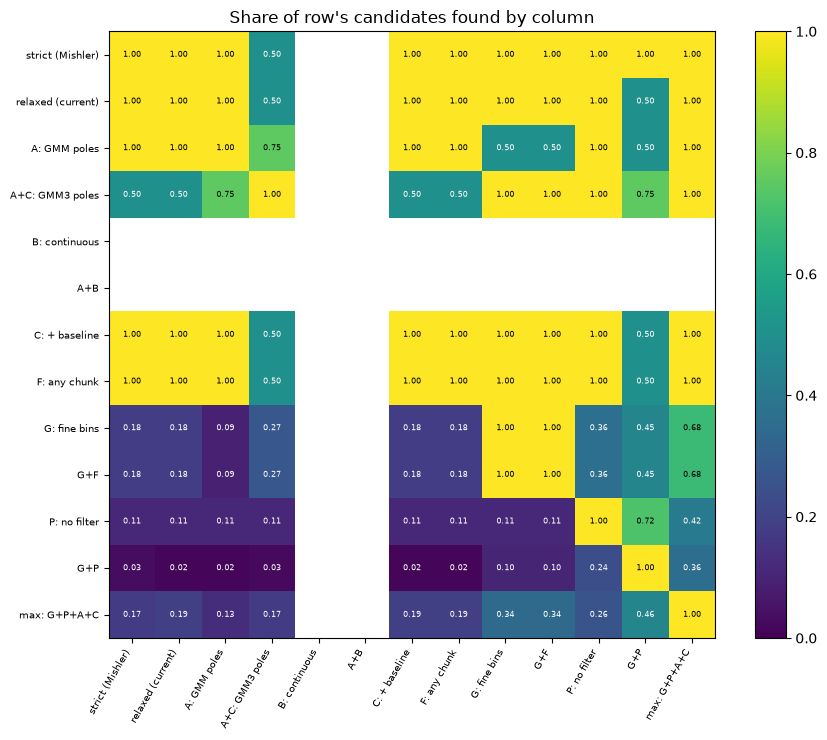

In [5]:
names_v = [v.name for v in core]
R = pd.DataFrame([[cm.matched_share([x for x in pl5 if x.variant == a], [x for x in pl5 if x.variant == b])
                   for b in names_v] for a in names_v], index=names_v, columns=names_v)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(R.values, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(names_v)), names_v, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(names_v)), names_v, fontsize=7)
for (i, j), val in np.ndenumerate(R.values):
    if np.isfinite(val):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6, color="white" if val < 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Share of row's candidates found by column")
fig.tight_layout(); save(fig, "3_redundancy"); plt.show()

## 4. Every channel: raw vs common-average-referenced EEG, and all LFP regions

Four variants per signal: relaxed (current), G+F (fine bins, any chunk), P (no filter) and the maximal combination. EEG runs twice: as recorded, and after subtracting the mean of the 26 valid EEG channels (idea D).

In [6]:
chan_variants = [V("relaxed (current)"), V("G+F", bins="fine", significance="any"), V("P: no filter", significance="none"),
                 V("max: G+P+A+C", bins="fine", significance="none", poles="gmm3", baseline=True)]
jobs = ([(s["key"], s["source"], False) for s in signals if s["kind"] == "eeg"]
        + [(s["key"] + "_car", s["source"], True) for s in signals if s["kind"] == "eeg"]
        + [(s["key"], s["source"], False) for s in signals if s["kind"] == "lfp"])
allc = cm.run_many(NWB, jobs, chan_variants, car_cache=CAR)
kind_of = lambda key: "EEG (CAR)" if key.endswith("_car") else ("EEG (raw)" if key.startswith("eeg") else "LFP")
rows = []
for group in ("EEG (raw)", "EEG (CAR)", "LFP"):
    for v in chan_variants:
        c = [x for x in allc if kind_of(x.signal) == group and x.variant == v.name and x.kind == "pole"]
        u = cm.unique(c)
        per = pd.Series([x.signal for x in c]).value_counts() if c else pd.Series(dtype=int)
        rows.append({"signals": group, "variant": v.name, "signals with candidates": per.size,
                     "pole candidates": len(c), "distinct (union)": len(u),
                     "broadband share": np.mean([x.broadband for x in c]) if c else np.nan,
                     "distinct, not broadband": sum(not x.broadband for x in u)})
chan = pd.DataFrame(rows).set_index(["signals", "variant"])
chan.to_csv(OUT / "channels_summary.csv")
chan.round(2)

signals with candidates  pole candidates  \
signals   variant                                                       
EEG (raw) relaxed (current)                       26              120   
          G+F                                     26              448   
          P: no filter                            26              938   
          max: G+P+A+C                            26             2914   
EEG (CAR) relaxed (current)                       26              114   
          G+F                                     26              508   
          P: no filter                            26              968   
          max: G+P+A+C                            26             2934   
LFP       relaxed (current)                       44              176   
          G+F                                     45              730   
          P: no filter                            45             1668   
          max: G+P+A+C                            45             5134   

                             distinct (union)  broadband share  \
signals   variant                                                
EEG (raw) relaxed (current)                30             0.28   
          G+F                             104             0.39   
          P: no filter                    690             0.10   
          max: G+P+A+C                    938             0.44   
EEG (CAR) relaxed (current)                28             0.44   
          G+F                             124             0.43   
          P: no filter                    750             0.09   
          max: G+P+A+C                   1044             0.49   
LFP       relaxed (current)                48             0.44   
          G+F                             142             0.49   
          P: no filter                   1128             0.09   
          max: G+P+A+C                   1238             0.49   

                             distinct, not broadband  
signals   variant                                     
EEG (raw) relaxed (current)                       22  
          G+F                                     74  
          P: no filter                           638  
          max: G+P+A+C                           719  
EEG (CAR) relaxed (current)                       20  
          G+F                                     94  
          P: no filter                           684  
          max: G+P+A+C                           751  
LFP       relaxed (current)                       26  
          G+F                                    106  
          P: no filter                          1056  
          max: G+P+A+C                           864

Does CAR change what EEG channels find? Average |r| between the candidates of different channels (higher = channels see the same motifs), and how many EEG candidates match an LFP candidate.

In [7]:
lfp_all = [x for x in allc if kind_of(x.signal) == "LFP"]
rows = []
for group in ("EEG (raw)", "EEG (CAR)"):
    c = [x for x in allc if kind_of(x.signal) == group and x.variant == "relaxed (current)" and x.kind == "pole"]
    T = np.array([x.template for x in c])
    sig = np.array([x.signal for x in c])
    C = np.abs(np.corrcoef(T)) if len(T) > 1 else np.zeros((1, 1))
    other = sig[:, None] != sig[None, :]
    rows.append({"EEG": group, "relaxed candidates": len(c), "mean |r| between channels": C[other].mean() if other.any() else np.nan,
                 "share matching an LFP candidate": cm.matched_share(c, lfp_all)})
pd.DataFrame(rows).round(2)

,EEG,relaxed candidates,mean |r| between channels,share matching an LFP candidate
0,EEG (raw),120,0.63,0.99
1,EEG (CAR),114,0.65,1.00


## 5. Union across channels: how fast do new candidates appear?

Channels added in random order (20 orders); distinct candidates in the union so far.

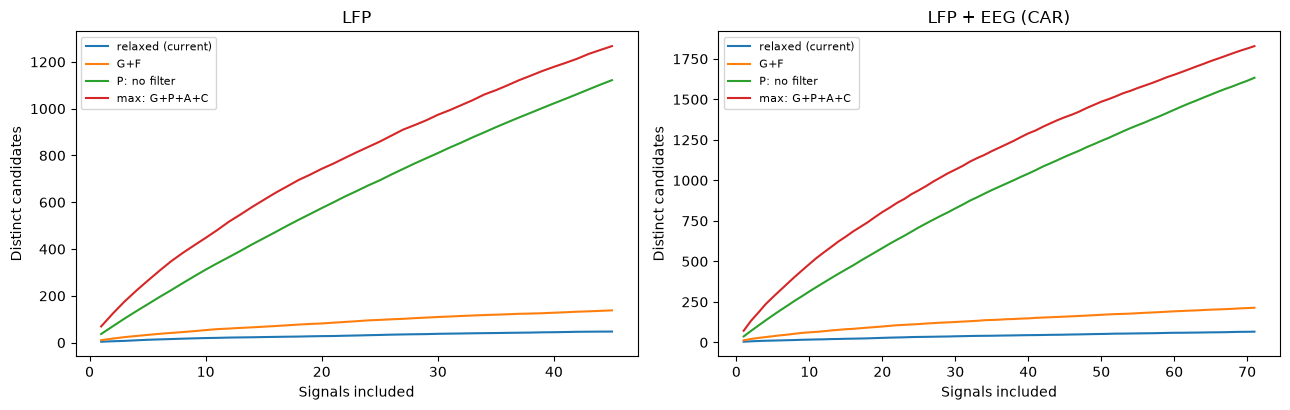

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
rng = np.random.default_rng(1)
for ax, group in zip(axes, (("LFP",), ("LFP", "EEG (CAR)"))):
    for v in chan_variants:
        c = [x for x in allc if kind_of(x.signal) in group and x.variant == v.name and x.kind == "pole"]
        keys = sorted({x.signal for x in allc if kind_of(x.signal) in group})
        curves = []
        for _ in range(20):
            order = {k: i for i, k in enumerate(rng.permutation(keys))}
            ranked = sorted(c, key=lambda x: order[x.signal])
            kept = cm.unique(ranked, sort=False)
            first = np.array([order[x.signal] for x in kept])
            curves.append([(first <= i).sum() for i in range(len(keys))])
        ax.plot(range(1, len(keys) + 1), np.mean(curves, axis=0), label=v.name)
    ax.set_xlabel("Signals included"); ax.set_ylabel("Distinct candidates")
    ax.set_title(" + ".join(group)); ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "6_union_accumulation"); plt.show()

In [9]:
grand = [x for x in allc if x.variant == "max: G+P+A+C" and x.kind == "pole" and kind_of(x.signal) != "EEG (raw)"]
u = cm.unique(grand)
print(f"Maximal combination over all LFP regions and CAR EEG: {len(grand)} pole candidates, {len(u)} distinct, "
      f"{sum(not x.broadband for x in u)} distinct and not broadband")
pd.Series([x.bin for x in u]).value_counts().rename("distinct candidates by time bin")

Maximal combination over all LFP regions and CAR EEG: 8068 pole candidates, 1810 distinct, 1312 distinct and not broadband


awake_electrical    554
awake               524
awake_visual        440
iso_visual           91
iso_early            81
iso_late             75
iso_electrical       45
Name: distinct candidates by time bin, dtype: int64

## 6. The candidates themselves, and their strength over the recording

Candidates from the fine-bins, any-chunk variant (G+F), which keeps a manageable number while covering every time bin.
For deep prelimbic LFP (PL5), and for the common-average-referenced EEG channel with the most candidates.

Strength over time: the whole recording (stimuli included) is z-scored per band, then projected onto each candidate's
band pattern, giving one value per second (10-s averages for display). Positive = the second looks like the
candidate.

In [10]:
SHOW = "G+F"

def candidate_set(signal, cands):
    return [x for x in cm.unique([x for x in cands if x.signal == signal and x.variant == SHOW]) if not x.broadband]

eeg_car_counts = pd.Series([x.signal for x in allc if x.signal.endswith("_car") and x.variant == SHOW and x.kind == "pole"
                            and not x.broadband]).value_counts()
EEG_KEY = eeg_car_counts.index[0]
views = {"lfp_PL5": (("lfp", "probeF", "PL5"), None, candidate_set("lfp_PL5", pl5)),
         EEG_KEY: (("eeg", int(EEG_KEY[3:-4])), CAR, candidate_set(EEG_KEY, allc))}
print({k: len(v[2]) for k, v in views.items()})

{'lfp_PL5': 10, 'eeg20_car': 10}


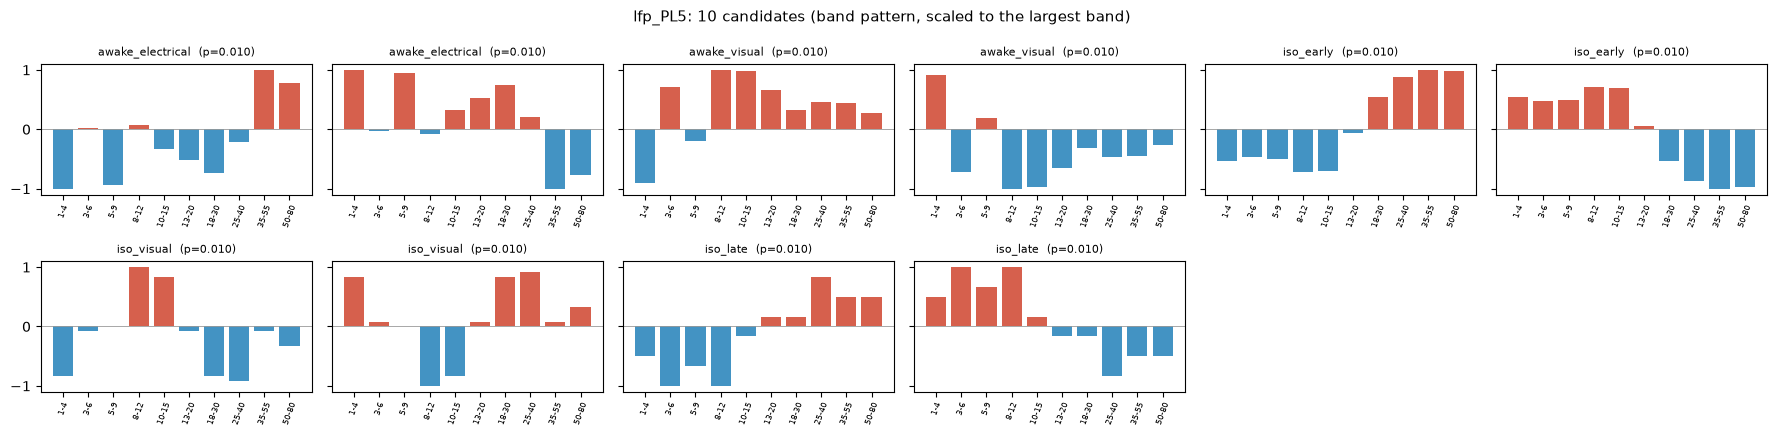

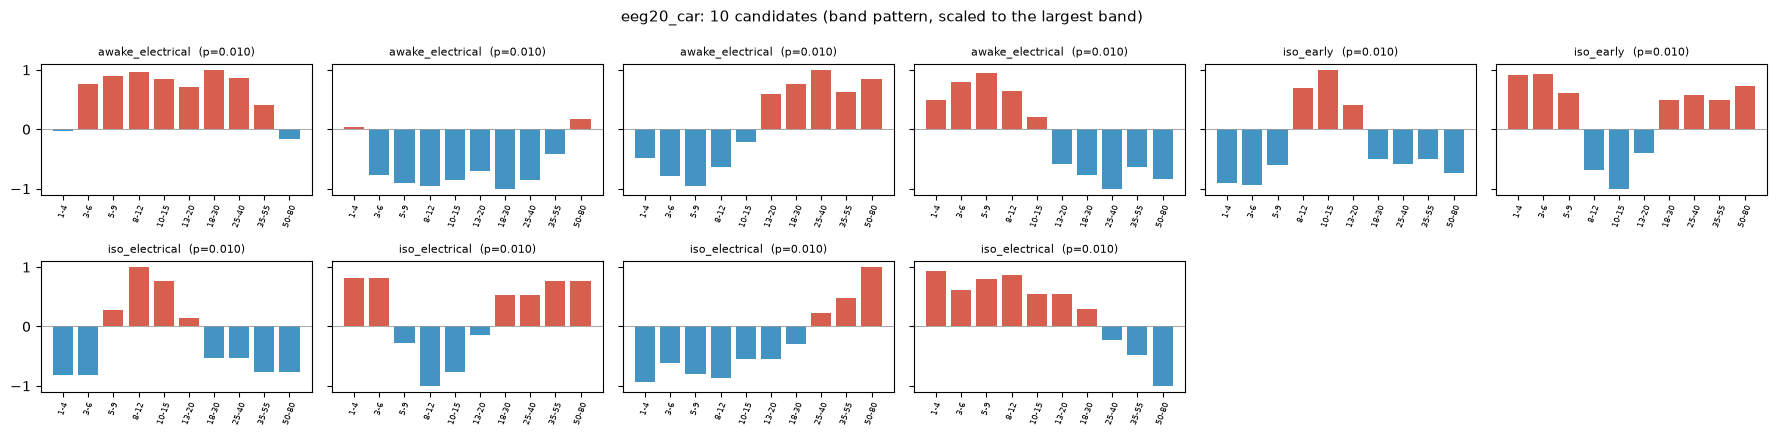

In [11]:
for key, (src, car, cands) in views.items():
    k = len(cands)
    cols = 6
    rows_ = int(np.ceil(k / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3.0 * cols, 2.2 * rows_), squeeze=False, sharey=True)
    for ax, c in zip(axes.flat, cands):
        tpl = c.template / np.abs(c.template).max()
        ax.bar(range(len(names)), tpl, color=np.where(tpl >= 0, "#d6604d", "#4393c3"))
        ax.axhline(0, color="0.6", lw=0.6)
        ax.set_title(f"{c.bin}  (p={c.p:.3f})", fontsize=8)
        ax.set_xticks(range(len(names)), names, rotation=70, fontsize=6)
    for ax in list(axes.flat)[k:]:
        ax.axis("off")
    fig.suptitle(f"{key}: {k} candidates (band pattern, scaled to the largest band)", fontsize=11)
    fig.tight_layout(); save(fig, f"6_templates_{key}"); plt.show()

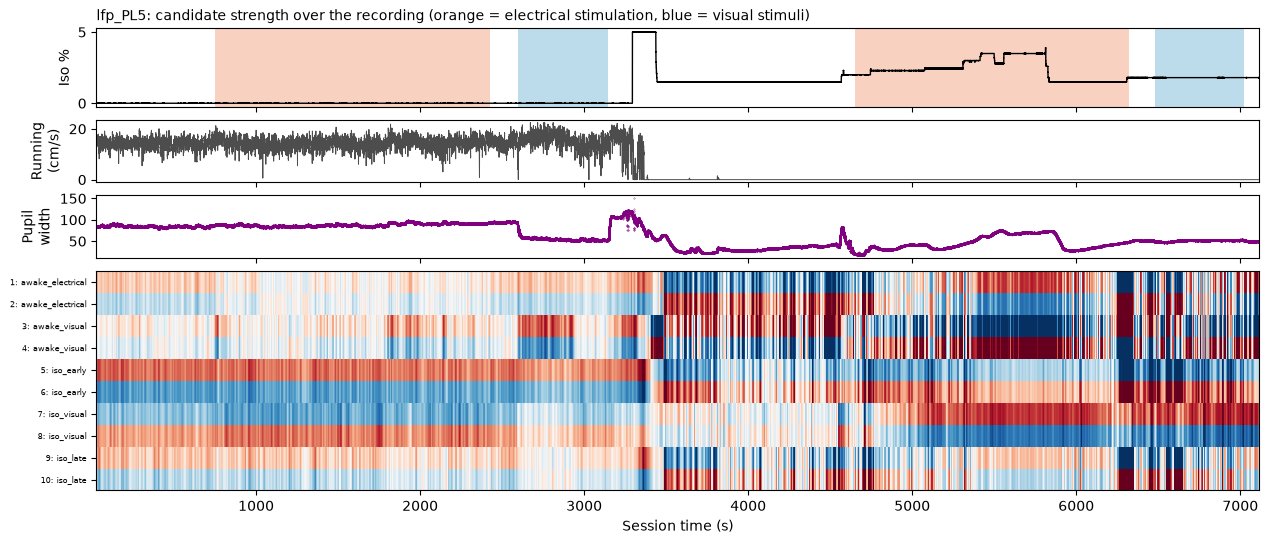

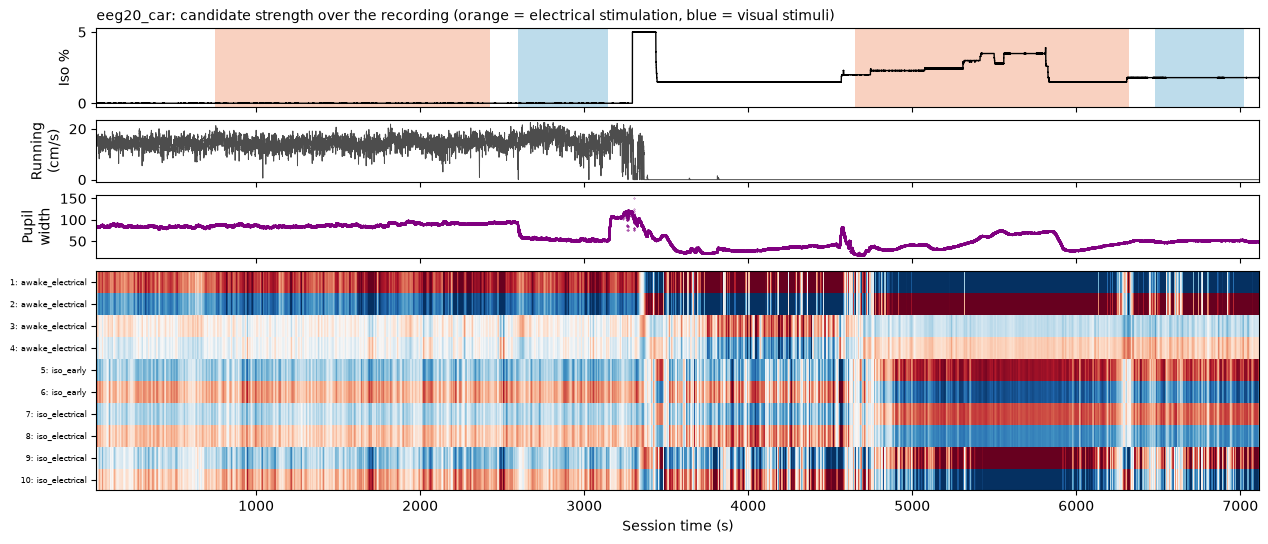

In [12]:
def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")

bins_ = cm.time_bins(info)
bin_of = lambda tt: next((b for b in cm.FINE_BINS if any(a <= tt < c for a, c in bins_[b])), None)
strength = {}
for key, (src, car, cands) in views.items():
    _, tt, env = cm.signal_envelope(NWB, src, car)
    Z = (env - env.mean(axis=0)) / env.std(axis=0, ddof=1)
    S = np.array([Z @ (c.template / np.linalg.norm(c.template)) for c in cands])
    strength[key] = (tt, S)
    fig = plt.figure(figsize=(15, 3.2 + 0.28 * len(cands)))
    gs = fig.add_gridspec(4, 1, height_ratios=[1, 0.8, 0.8, max(2, 0.28 * len(cands))], hspace=0.12)
    ax0 = fig.add_subplot(gs[0])
    ax0.plot(info.iso_t, info.iso_level, color="k", lw=1); ax0.set_ylabel("Iso %")
    for lab, a, b in info.stim_blocks:
        ax0.axvspan(a, b, color="#f4a582", alpha=0.5, lw=0)
    for lab, a, b in info.visual_blocks:
        ax0.axvspan(a, b, color="#92c5de", alpha=0.6, lw=0)
    ax0.set_title(f"{key}: candidate strength over the recording (orange = electrical stimulation, blue = visual stimuli)",
                  fontsize=10, loc="left")
    ax1 = fig.add_subplot(gs[1], sharex=ax0)
    ax1.plot(run_t, smooth(run_speed, 100), color="0.3", lw=0.7); ax1.set_ylabel("Running\n(cm/s)")
    ax2 = fig.add_subplot(gs[2], sharex=ax0)
    ax2.plot(pupil_t, pupil, ".", ms=0.5, color="purple"); ax2.set_ylabel("Pupil\nwidth")
    ax3 = fig.add_subplot(gs[3], sharex=ax0)
    ax3.imshow(np.array([smooth(s, 10) for s in S]), aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2, interpolation="none",
               extent=[tt[0], tt[-1], len(cands) - 0.5, -0.5])
    ax3.set_yticks(range(len(cands)), [f"{i + 1}: {c.bin}" for i, c in enumerate(cands)], fontsize=6)
    ax3.set_xlabel("Session time (s)")
    for ax in (ax0, ax1, ax2):
        plt.setp(ax.get_xticklabels(), visible=False)
    ax0.set_xlim(tt[0], tt[-1])
    save(fig, f"6_strength_over_time_{key}"); plt.show()

Average strength of each candidate in each time bin (rows: candidates, numbered as above; label = bin it was found in), and its correlation with running speed and pupil size during spontaneous awake seconds.

In [13]:
for key, (src, car, cands) in views.items():
    tt, S = strength[key]
    which = np.array([bin_of(x) for x in tt], dtype=object)
    order = [b for b in cm.FINE_BINS if (which == b).any()]
    table = pd.DataFrame([[S[i, which == b].mean() for b in order] for i in range(len(cands))],
                         index=[f"{i + 1}: {c.bin}" for i, c in enumerate(cands)], columns=order)
    awake = which == "awake"
    run_ = np.interp(tt, run_t, smooth(run_speed, 100))
    pup_ = np.interp(tt, pupil_t[np.isfinite(pupil)], pupil[np.isfinite(pupil)])
    table["r with running (awake)"] = [np.corrcoef(S[i, awake], run_[awake])[0, 1] for i in range(len(cands))]
    table["r with pupil (awake)"] = [np.corrcoef(S[i, awake], pup_[awake])[0, 1] for i in range(len(cands))]
    print(key)
    display(table.round(2).style.background_gradient(cmap="RdBu_r", vmin=-1.5, vmax=1.5, axis=None))

lfp_PL5


,awake,awake_electrical,awake_visual,iso_early,iso_electrical,iso_visual,iso_late,r with running (awake),r with pupil (awake)
1: awake_electrical,0.520000,0.120000,0.460000,-1.230000,0.330000,-0.190000,-0.150000,0.130000,0.170000
2: awake_electrical,-0.520000,-0.120000,-0.460000,1.230000,-0.330000,0.190000,0.150000,-0.130000,-0.170000
3: awake_visual,0.190000,0.320000,0.790000,0.920000,-1.130000,-0.640000,-0.570000,0.110000,0.500000
4: awake_visual,-0.190000,-0.320000,-0.790000,-0.920000,1.130000,0.640000,0.570000,-0.110000,-0.500000
5: iso_early,1.130000,1.070000,0.840000,-0.740000,-0.900000,-1.490000,-1.370000,-0.050000,-0.180000
6: iso_early,-1.130000,-1.070000,-0.840000,0.740000,0.900000,1.490000,1.370000,0.050000,0.180000
7: iso_visual,-0.780000,-1.030000,-0.490000,-0.070000,1.100000,1.420000,1.440000,0.010000,0.370000
8: iso_visual,0.780000,1.030000,0.490000,0.070000,-1.100000,-1.420000,-1.440000,-0.010000,-0.370000
9: iso_late,0.550000,0.430000,0.130000,-0.650000,-0.070000,-0.720000,-0.530000,-0.130000,-0.270000
10: iso_late,-0.550000,-0.430000,-0.130000,0.650000,0.070000,0.720000,0.530000,0.130000,0.270000


eeg20_car


,awake,awake_electrical,awake_visual,iso_early,iso_electrical,iso_visual,iso_late,r with running (awake),r with pupil (awake)
1: awake_electrical,1.270000,1.530000,1.500000,2.090000,-3.160000,-2.380000,-2.660000,-0.030000,0.290000
2: awake_electrical,-1.270000,-1.530000,-1.500000,-2.090000,3.160000,2.380000,2.660000,0.030000,-0.290000
3: awake_electrical,0.180000,0.050000,0.090000,0.740000,-0.450000,-0.520000,-0.550000,-0.000000,-0.070000
4: awake_electrical,-0.180000,-0.050000,-0.090000,-0.740000,0.450000,0.520000,0.550000,0.000000,0.070000
5: iso_early,-0.710000,-0.720000,-0.790000,-0.740000,1.400000,1.300000,1.290000,-0.070000,-0.060000
6: iso_early,0.710000,0.720000,0.790000,0.740000,-1.400000,-1.300000,-1.290000,0.070000,0.060000
7: iso_electrical,-0.530000,-0.500000,-0.570000,-0.770000,1.100000,1.110000,1.100000,-0.060000,0.070000
8: iso_electrical,0.530000,0.500000,0.570000,0.770000,-1.100000,-1.110000,-1.100000,0.060000,-0.070000
9: iso_electrical,-0.490000,-0.730000,-0.660000,-0.990000,1.500000,0.970000,1.150000,0.020000,-0.170000
10: iso_electrical,0.490000,0.730000,0.660000,0.990000,-1.500000,-0.970000,-1.150000,-0.020000,0.170000


## Conclusions

**How many candidates each idea adds** (deep prelimbic LFP, distinct after merging near-duplicates):

| Variant | Distinct candidates | vs. current |
|---|---|---|
| Current relaxed version | 4 | 1× |
| F: present in any chunk | 4 | same as current |
| C: + baseline label | 4 | same (adds labels, not patterns) |
| A: Gaussian-mixture poles | 4 | same |
| B: no binarization | 0 | fewer |
| G: finer time bins | 18 | 4.5× |
| P: keep everything, p-value as a score | 36 | 9× |
| G+P | 108 | 27× |

**Across all 45 LFP regions:** 48 distinct candidates with the current version, against 1,238 with the maximal combination.

**Adding the common-average-referenced EEG:** 1,810 distinct candidates, of which 1,312 are not broadband-like.

**Idea by idea**

- **P (stop filtering, keep the p-value as a score)** is by far the biggest lever, and **G (finer time bins)** is the second. Most fine-bin candidates come from awake and stimulus-evoked bins.
- **Union across channels (E):** without the filter, the count keeps rising almost linearly as channels are added and never levels off. Patterns that recur across regions would make the curve flatten, so most unfiltered candidates are probably specific to one channel. **Counting in how many channels a candidate recurs is a free reproducibility score to rank by before spike validation.**
- **A, Gaussian-mixture poles:** with 2 components the poles are always exact opposites in shape (an arithmetic consequence of z-scoring), so they add nothing new. 3 components (low, middle, high) can produce poles that differ in shape (r = 0.6 for one isoflurane axis), but their templates absorb the broadband up/down shift, so most are flagged broadband-like. Better used to measure expression (responsibility) than to discover patterns.
- **B, no binarization:** found nothing on PL5. The sign step helps detection with this significance test.
- **F, any chunk:** identical to the current version, as expected (the every-chunk rule was already weak).
- **C, baseline:** adds a label, not a pattern. Useful so that every second has a label.
- **D, common average reference:** about the same number of EEG candidates (28 vs 30 distinct) and a higher broadband share (0.44 vs 0.28). Channels still share similar patterns (mean |r| 0.65 vs 0.63), and 100% of EEG candidates have a match among the LFP candidates. It does not add candidates.

**What the motifs look like over time**

- **Over the whole recording, candidate strength mostly follows slow changes:** the switch at isoflurane induction, the stimulus blocks, and changes in isoflurane level. Each candidate's average strength differs strongly between time bins.
- **Moment-to-moment fluctuation is visible but smaller.** Z-scoring within each bin would show it better.
- **Behaviour:** one PL5 candidate tracks pupil size during spontaneous awake time (r = 0.50); none tracks running much (|r| ≤ 0.13).
- **Early isoflurane can look like awake:** the stretch right after induction (1.5%) often resembles the awake state on these axes.